In [1]:
# Run from manual_notebooks/. Restart the kernel after changing this path.
import os

os.environ["YOLO_CONFIG_DIR"] = "../experiments/.ultralytics"


In [2]:
import time

from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import cv2
import numpy as np

from ultralytics import YOLO, settings
import torch

Проверяем имеющийся датасет

In [13]:

ROOT = Path("../")
DATASETS_DIR = ROOT / "data"
WEIGHTS_DIR = ROOT / "weights"
ORIGINAL_WEIGHTS_DIR = WEIGHTS_DIR / "original"
TRAINED_WEIGHTS_DIR = WEIGHTS_DIR / "trained"

ORIGINAL_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
TRAINED_WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR = ROOT / "experiments/reproductions"

DATASET_PATH = DATASETS_DIR / "tobacco_yolo"

settings.update({
    "datasets_dir": str(DATASETS_DIR.resolve()),
    "weights_dir": str(ORIGINAL_WEIGHTS_DIR.resolve()),
    "runs_dir": str(RUNS_DIR.resolve()),
})

for key in ("datasets_dir", "weights_dir", "runs_dir"):
    print(f"{key}: {settings[key]}")


print(DATASET_PATH)

datasets_dir: /home/natsusa/academic/tobacco-article/data
weights_dir: /home/natsusa/academic/tobacco-article/weights/original
runs_dir: /home/natsusa/academic/tobacco-article/experiments/reproductions
../data/tobacco_yolo


Устанавливаем нужный девайс

In [4]:
# Select an available device, or set explicitly: "cpu", "cuda:0", "cuda:1", "mps".
if torch.cuda.is_available():
    device = "cuda:0"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Device: {device}")


Device: cpu


Пример генерации

In [5]:
# Очистка памяти GPU перед запуском
if torch.device(device).type == "cuda":
    with torch.cuda.device(device):
        torch.cuda.empty_cache()

model_name = "yolo26n.pt"

model = YOLO(ORIGINAL_WEIGHTS_DIR / model_name)
model.to(device)
model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

обучаем как есть

In [6]:
data_yaml = DATASET_PATH / "data.generated.yaml" 

model.train(
    data=data_yaml,
    epochs=5,  
    imgsz=640,
    batch=1,  
    device=device,
    amp=True, 
    workers=8,

    lr0=0.005,
    lrf=0.1,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=5,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,
    cos_lr=True,

    augment=True,
    mosaic=0.8,
    mixup=0.3,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    
    patience=15, 
    save_period=1,
    cache="disk",
    plots=True
)

Ultralytics 8.4.191 🚀 Python-3.14.7 torch-2.14.1+cu130 CPU (12th Gen Intel Core i3-1215U)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=../data/tobacco_yolo/data.generated.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.005, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.3, mode=train, model=../weights/yolo26n.pt, momentum=0.937, mosaic=0.8, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=N

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fb528bce450>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [16]:
# Copy the best checkpoint under the original model name.
# A later run of the same model replaces this copy; run checkpoints stay intact.
import shutil

best_checkpoint = Path(model.trainer.best)
if not best_checkpoint.is_file():
    raise FileNotFoundError(f"Best checkpoint not found: {best_checkpoint}")

trained_model_path = TRAINED_WEIGHTS_DIR / Path(model_name).name
shutil.copy2(best_checkpoint, trained_model_path)
print(f"Trained weights: {trained_model_path}")
# To load later: model = YOLO(trained_model_path).to(device)


Trained weights: ../weights/trained/yolo26n.pt



0: 384x640 31 tobaccos, 54.0ms
Speed: 1.9ms preprocess, 54.0ms inference, 0.6ms postprocess per image at shape (1, 3, 384, 640)


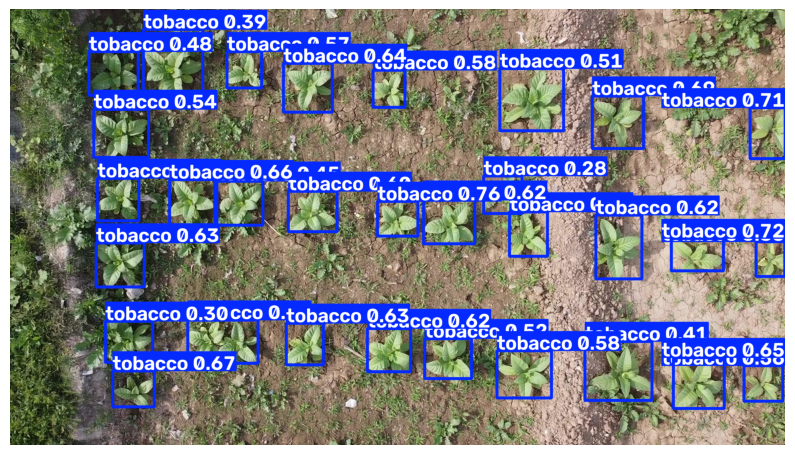

In [7]:

results = model([DATASET_PATH / "images" / "00a357bc-17.jpg"], device=device)  # return a list of Results objects

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    obb = result.obb  # Oriented boxes object for OBB outputs
    # result.show()  # display to screen
    annotated_img_point = result.plot()
    annotated_img_point = cv2.cvtColor(annotated_img_point, cv2.COLOR_BGR2RGB)

    # Отображаем результат
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img_point)
    plt.axis("off")
    plt.show()


0: 384x640 31 tobaccos, 35.7ms
Speed: 1.4ms preprocess, 35.7ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)


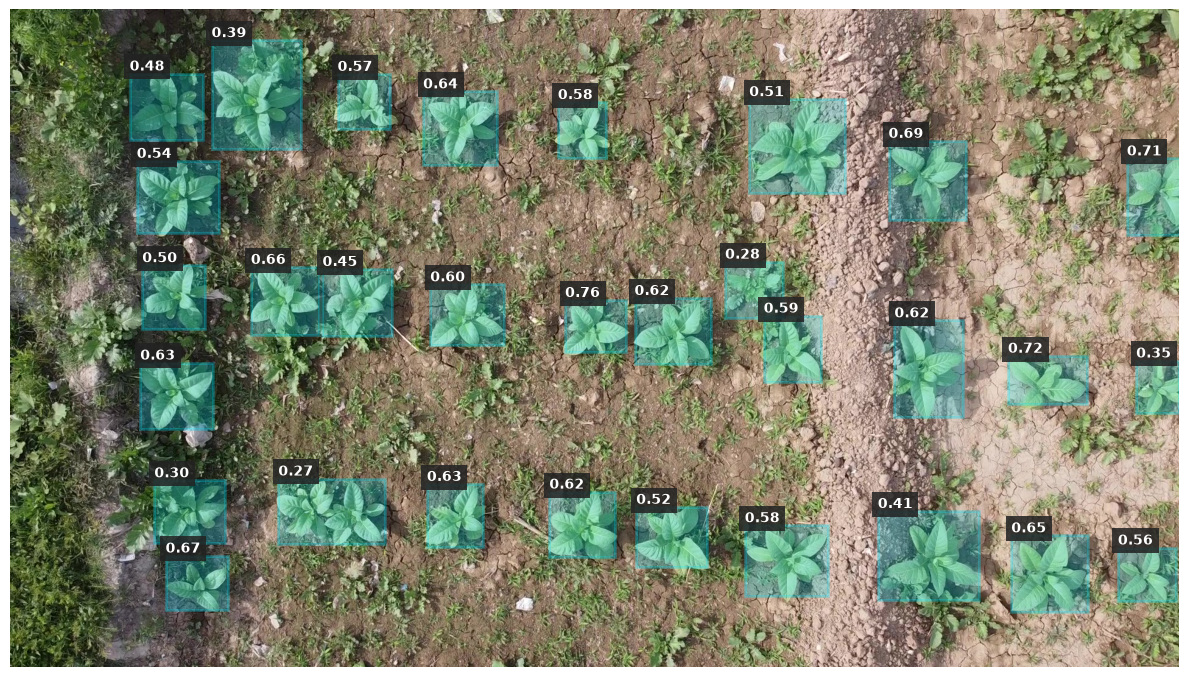

In [8]:
results = model([DATASET_PATH / "images" / "00a357bc-17.jpg"], device=device)

for result in results:
    img = cv2.cvtColor(result.orig_img, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    if result.boxes is not None:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            cls_id = int(box.cls[0])
            conf = float(box.conf[0])

            class_name = result.names[cls_id]

            # Your own custom style
            color = "#00E5FF"

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor=color,
                facecolor=color,
                alpha=0.25
            )

            ax.add_patch(rect)

            # Label with background
            ax.text(
                x1,
                max(0, y1 - 5),
                # f"{class_name} {conf:.2f}",
                f"{conf:.2f}",
                color="white",
                fontsize=10,
                fontweight="bold",
                bbox={
                    "facecolor": "#222222",
                    "alpha": 0.85,
                    "edgecolor": "none",
                    "pad": 4
                }
            )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

Проверка fps

In [9]:
img = cv2.imread(str(DATASET_PATH / "images" / "00a357bc-17.jpg"))

def synchronize():
    if str(model.device).startswith("cuda"):
        torch.cuda.synchronize(model.device)
    elif str(model.device).startswith("mps"):
        torch.mps.synchronize()

print(f"Timing device: {model.device}")

# Warmup
for _ in range(200):
    model.predict(img, verbose=False, device=device)

synchronize()

latencies = []

# Benchmark
for _ in range(2000):
    synchronize()
    start = time.perf_counter()

    results = model.predict(
        img,
        device=device,
        verbose=False,
        imgsz=640,
        conf=0.5
    )

    # Simulate decision-making from detections
    boxes = results[0].boxes

    if boxes is not None and len(boxes) > 0:
        # Example: make a decision based on class IDs
        detected_classes = boxes.cls.cpu().numpy()
        obstacle_detected = np.any(detected_classes == 0)
    else:
        obstacle_detected = False

    synchronize()
    latencies.append(
        (time.perf_counter() - start) * 1000
    )

latencies = np.array(latencies)

print(f"Mean latency: {latencies.mean():.2f} ms")
print(f"Median latency: {np.median(latencies):.2f} ms")
print(f"P95 latency: {np.percentile(latencies, 95):.2f} ms")
print(f"P99 latency: {np.percentile(latencies, 99):.2f} ms")
print(f"Estimated FPS: {1000 / latencies.mean():.2f}")

Timing device: cpu
Mean latency: 37.93 ms
Median latency: 35.62 ms
P95 latency: 43.08 ms
P99 latency: 47.44 ms
Estimated FPS: 26.37


In [17]:
from synthetic_stream import SyntheticStream

Processed: 300 frames
Effective FPS: 25.07


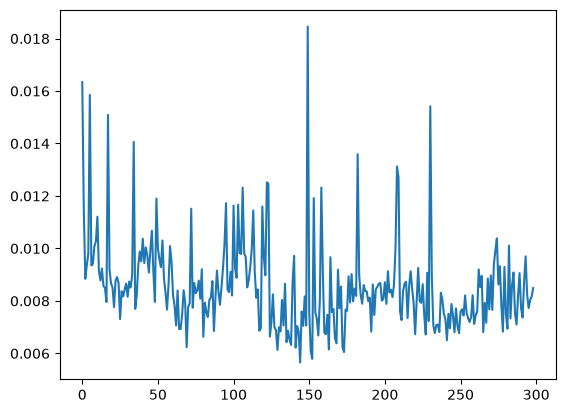

In [18]:
img = cv2.imread(
    str(DATASET_PATH / "images" / "00a357bc-17.jpg")
)

stream = SyntheticStream(img, fps=300)

latencies = []

try:
    results = model.predict(
        source=stream,
        device=device,
        stream=True,
        imgsz=640,
        verbose=False,
        save=False,
        show=False
    )

    start = time.perf_counter()
    frame_count = 0

    for result in results:
        start_2 = time.perf_counter()
        boxes = result.boxes

        # Robot logic
        obstacle_detected = boxes is not None and len(boxes) > 0
        action = "STOP" if obstacle_detected else "MOVE"

        frame_count += 1

        if frame_count >= 300:
            break

        latencies.append((time.perf_counter() - start_2) * 1000)

    elapsed = time.perf_counter() - start

    print(f"Processed: {frame_count} frames")
    print(f"Effective FPS: {frame_count / elapsed:.2f}")

finally:
    stream.close()

plt.plot(latencies)